### Zum Winde verweht – Lösung Schritt für Schritt

*Jugendwettbewerb Informatik 2021, 3. Runde, Junioraufgabe 1 (= 40. Bundeswettbewerb Informatik, 1. Runde, Junioraufgabe 1)*

Die 10H-Regelung schreibt vor, dass eine Windkraftanlage mit einer Höhe von H Metern einen Abstand von mindestens 10H Metern
zu allen Wohngebäuden haben muss.

#### Junioraufgabe 1

Schreibe ein Programm, das für einen flachen Landkreis eine Liste mit den Koordinaten aller Wohngebäude und eine zweite
Liste mit gewünschten Standorten von neuen Windkraftanlagen einliest und eine Liste ausgibt, in der für jeden Standort
vermerkt ist, wie hoch die dort zu bauende Windkraftanlage maximal sein darf. Die Ausdehnungen der Gebäude und der
Windkraftanlagen in den vier Himmelsrichtungen darfst du dabei außer Acht lassen.

Wende dein Programm mindestens auf alle Beispiele an, die du auf den BWINF-Webseiten findest, und dokumentiere die Ergebnisse.

#### Beispieldaten

Im Ordner `beispieldaten` stehen `landkreis1.txt` bis `landkreis4.txt`. Jede Datei ist so aufgebaut:

- 1. Zeile: Anzahl `n` der Häuser und Anzahl `m` der Windräder
- die nächsten `n` Zeilen: Koordinaten `x y` der Häuser (in Metern)
- die nächsten `m` Zeilen: Koordinaten `x y` der geplanten Windräder

## Was dir bei dieser Aufgabe hilft

**Algorithmische Kenntnisse**
- **Abstand zweier Punkte:** Nach dem Satz des Pythagoras ist der Abstand von `(x1, y1)` und `(x2, y2)` gleich
  `Wurzel((x1 - x2)² + (y1 - y2)²)`.
- **Minimum suchen (lineare Suche):** Für jedes Windrad gehen wir alle Häuser durch und merken uns den kleinsten Abstand.
- **Verschachtelte Schleifen:** Außen die Windräder, innen die Häuser. Das sind `n · m` Abstände, also bei 10 000 Häusern und 30 Windrädern
  rund 300 000, für einen Computer sehr wenig.
- **Rechnen mit Kommazahlen und Runden** für die Ausgabe.
- Für **sehr viele** Häuser und Windräder gibt es schnellere Verfahren: räumliche Suchstrukturen wie den k-d-Baum (nächster Nachbar),
  oder ein Voronoi-Diagramm. Das ist hier nicht nötig.

**Nützliche Funktionen und Bibliotheken**
- `math.sqrt` (Quadratwurzel), `math.hypot(dx, dy)` (Abstand zu einem Punkt, wenn man die Unterschiede kennt) und `min`
- Zum Zeichnen: `matplotlib.pyplot` (optional)
- `f'{zahl:.2f}'` formatiert eine Zahl mit zwei Nachkommastellen
- Für große Probleme: `scipy.spatial.cKDTree` findet nächste Nachbarn sehr schnell (hier nicht nötig)

## Die Idee

Ein Windrad der Höhe `H` darf nur gebaut werden, wenn **jedes** Haus mindestens `10 · H` Meter entfernt ist. Sei `r` der Abstand zum
**nächsten** Haus. Dann gilt für alle Häuser Abstand ≥ `r`, also darf `10 · H ≤ r` sein, und die größte erlaubte Höhe ist

`H = r / 10`

Für jedes Windrad müssen wir also nur das **nächstgelegene Haus** finden. Anschaulich: Wir zeichnen um das Windrad einen Kreis, der so groß
ist, dass kein Haus im Inneren liegt. Der Radius dieses Kreises ist `r`.

## Schritt 1: Die Datei einlesen

Alle Zahlen werden mit `split()` in eine Liste gelesen. Die ersten beiden sind `n` und `m`, danach kommen die Koordinaten:
zuerst `n` Paare für die Häuser, dann `m` Paare für die Windräder. Wir speichern jedes Haus und jedes Windrad als kleine Liste `[x, y]`.
Die Koordinaten können Kommazahlen sein, deshalb benutzen wir `float(...)`.

In [ ]:
def lies_landkreis(dateiname):
    with open(dateiname, encoding='utf-8') as f:
        zahlen = f.read().split()
    n = int(zahlen[0])
    m = int(zahlen[1])
    i = 2                                       # Position der nächsten Zahl
    haeuser = []
    for k in range(n):
        haeuser.append([float(zahlen[i]), float(zahlen[i + 1])])
        i = i + 2
    windraeder = []
    for k in range(m):
        windraeder.append([float(zahlen[i]), float(zahlen[i + 1])])
        i = i + 2
    return haeuser, windraeder


haeuser, windraeder = lies_landkreis('beispieldaten/landkreis1.txt')
print(len(haeuser), 'Häuser, erstes Haus:', haeuser[0])
print(len(windraeder), 'Windräder:', windraeder)

12 Häuser, erstes Haus: [-82.0, -315.0]
3 Windräder: [[1242.0, -593.0], [-1223.0, -1479.0], [1720.0, 401.0]]


## Schritt 2: Der Abstand

Mit dem Satz des Pythagoras: Die Unterschiede der Koordinaten sind die Katheten eines rechtwinkligen Dreiecks, der Abstand ist die
Hypotenuse. `math.sqrt(...)` berechnet die Quadratwurzel.

In [ ]:
import math


def abstand(x1, y1, x2, y2):
    dx = x1 - x2
    dy = y1 - y2
    return math.sqrt(dx * dx + dy * dy)


print(abstand(0, 0, 3, 4))          # das 3-4-5-Dreieck
print(abstand(-82, -315, 248, 714))

5.0
1080.6206549941567


## Schritt 3: Das nächste Haus finden

Für ein Windrad gehen wir alle Häuser durch und merken uns den kleinsten Abstand. Als Startwert nehmen wir den Abstand zum ersten Haus.
(Die Aufgabe garantiert, dass es mindestens ein Haus gibt.) Dann ersetzen wir ihn, sobald ein Haus näher ist.
Wir merken uns auch, **welches** Haus das ist, das hilft später beim Kontrollieren.

In [ ]:
def naechstes_haus(haeuser, wx, wy):
    bester_abstand = abstand(wx, wy, haeuser[0][0], haeuser[0][1])
    bestes_haus = 0
    for nr in range(1, len(haeuser)):
        a = abstand(wx, wy, haeuser[nr][0], haeuser[nr][1])
        if a < bester_abstand:
            bester_abstand = a
            bestes_haus = nr
    return bester_abstand, bestes_haus


for wx, wy in windraeder:
    r, nr = naechstes_haus(haeuser, wx, wy)
    print(f'Windrad bei ({wx:.0f}, {wy:.0f}): nächstes Haus ist Nummer {nr}, Abstand {r:.2f} m')

Windrad bei (1242, -593): nächstes Haus ist Nummer 9, Abstand 485.23 m
Windrad bei (-1223, -1479): nächstes Haus ist Nummer 5, Abstand 1589.80 m
Windrad bei (1720, 401): nächstes Haus ist Nummer 2, Abstand 724.13 m


## Schritt 4: Die maximale Höhe

Die erlaubte Höhe ist ein Zehntel des Abstands zum nächsten Haus. Wir sammeln die Höhen für alle Windräder in einer Liste und
geben sie auf zwei Nachkommastellen gerundet aus.

In [ ]:
def maximale_hoehen(haeuser, windraeder):
    hoehen = []
    for wx, wy in windraeder:
        r, nr = naechstes_haus(haeuser, wx, wy)
        hoehen.append(r / 10)
    return hoehen


def bearbeite(dateiname):
    haeuser, windraeder = lies_landkreis(dateiname)
    hoehen = maximale_hoehen(haeuser, windraeder)
    print(f'{dateiname}: {len(haeuser)} Häuser, {len(windraeder)} Windräder')
    for nr in range(len(hoehen)):
        print(f'  Windrad {nr + 1:2} bei ({windraeder[nr][0]:8.1f}, {windraeder[nr][1]:8.1f}): maximal {hoehen[nr]:7.2f} m hoch')


bearbeite('beispieldaten/landkreis1.txt')

beispieldaten/landkreis1.txt: 12 Häuser, 3 Windräder
  Windrad  1 bei (  1242.0,   -593.0): maximal   48.52 m hoch
  Windrad  2 bei ( -1223.0,  -1479.0): maximal  158.98 m hoch
  Windrad  3 bei (  1720.0,    401.0): maximal   72.41 m hoch


Das erste Windrad darf also 48,52 m hoch werden, das zweite 158,98 m und das dritte 72,41 m. Das sind genau die Werte aus den Lösungshinweisen.

## Schritt 5: Alle Beispiele

`landkreis3.txt` hat 2382 Häuser und 16 Windräder, `landkreis4.txt` hat 9993 Häuser und 30 Windräder. Das sind etwa 38 000 und 300 000 Abstände,
das Programm braucht dafür nur einen Bruchteil einer Sekunde.

In [ ]:
for nr in range(1, 5):
    bearbeite(f'beispieldaten/landkreis{nr}.txt')

beispieldaten/landkreis1.txt: 12 Häuser, 3 Windräder
  Windrad  1 bei (  1242.0,   -593.0): maximal   48.52 m hoch
  Windrad  2 bei ( -1223.0,  -1479.0): maximal  158.98 m hoch
  Windrad  3 bei (  1720.0,    401.0): maximal   72.41 m hoch
beispieldaten/landkreis2.txt: 94 Häuser, 15 Windräder
  Windrad  1 bei (   359.0,     20.0): maximal  115.16 m hoch
  Windrad  2 bei (     2.0,   -773.0): maximal  201.25 m hoch
  Windrad  3 bei (   315.0,   -213.0): maximal  138.85 m hoch
  Windrad  4 bei (  -629.0,   -532.0): maximal  209.12 m hoch
  Windrad  5 bei (    97.0,    -69.0): maximal  132.01 m hoch
  Windrad  6 bei (  -392.0,   -418.0): maximal  186.16 m hoch
  Windrad  7 bei (    87.0,   -384.0): maximal  161.68 m hoch
  Windrad  8 bei (  -597.0,    612.0): maximal  133.30 m hoch
  Windrad  9 bei (   -13.0,    -32.0): maximal  133.54 m hoch
  Windrad 10 bei (   -57.0,     49.0): maximal  128.77 m hoch
  Windrad 11 bei (   276.0,    292.0): maximal   91.78 m hoch
  Windrad 12 bei (   156.

Beim ersten Windrad von `landkreis4.txt` steht 0,00 m: Es soll direkt auf einem Haus stehen, dort darf es keine Höhe haben.

## Für Neugierige: Zeichnen und beschleunigen

**Zeichnung:** Wir zeichnen die Häuser als schwarze Punkte, die Windräder als rote Kreuze und um jedes Windrad den Kreis mit dem
Radius `r`. Im Inneren eines Kreises liegt kein Haus, und am Rand liegt mindestens ein Haus. So kann man die Ergebnisse sofort überprüfen.

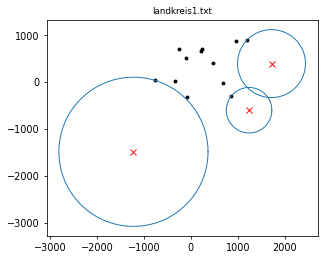

In [ ]:
import matplotlib.pyplot as plt


def zeichne(dateiname):
    haeuser, windraeder = lies_landkreis(dateiname)
    plt.figure(figsize=(5, 5))
    xs = []
    ys = []
    for x, y in haeuser:
        xs.append(x)
        ys.append(y)
    plt.plot(xs, ys, 'k.', markersize=6)
    for wx, wy in windraeder:
        r, nr = naechstes_haus(haeuser, wx, wy)
        kx = []
        ky = []
        for grad in range(361):
            kx.append(wx + r * math.cos(math.radians(grad)))
            ky.append(wy + r * math.sin(math.radians(grad)))
        plt.plot(kx, ky, color='tab:blue', linewidth=1)
        plt.plot([wx], [wy], 'rx')
    plt.gca().set_aspect('equal')
    plt.title(dateiname.split('/')[-1], fontsize=9)
    plt.show()


zeichne('beispieldaten/landkreis1.txt')

**Beschleunigen:** Die Wurzel ist für den Computer teurer als eine Multiplikation. Um das **kleinste** Haus zu finden, muss man nicht den
Abstand selbst vergleichen, es genügt das **Quadrat** des Abstands (`dx² + dy²`), denn die Reihenfolge der Zahlen bleibt dieselbe. Die Wurzel
berechnen wir dann nur einmal pro Windrad, für das nächste Haus. Das Ergebnis muss genau gleich sein:

In [ ]:
def naechster_abstand_schnell(haeuser, wx, wy):
    kleinstes_quadrat = None
    for hx, hy in haeuser:
        dx = wx - hx
        dy = wy - hy
        quadrat = dx * dx + dy * dy
        if kleinstes_quadrat is None or quadrat < kleinstes_quadrat:
            kleinstes_quadrat = quadrat
    return math.sqrt(kleinstes_quadrat)


for nr in range(1, 5):
    haeuser, windraeder = lies_landkreis(f'beispieldaten/landkreis{nr}.txt')
    gleich = True
    for wx, wy in windraeder:
        if abs(naechster_abstand_schnell(haeuser, wx, wy) - naechstes_haus(haeuser, wx, wy)[0]) > 1e-9:
            gleich = False
    print(f'landkreis{nr}.txt: beide Verfahren liefern dasselbe: {gleich}')

landkreis1.txt: beide Verfahren liefern dasselbe: True
landkreis2.txt: beide Verfahren liefern dasselbe: True
landkreis3.txt: beide Verfahren liefern dasselbe: True
landkreis4.txt: beide Verfahren liefern dasselbe: True


Bei Millionen von Häusern und vielen Windrädern wird auch das zu langsam, denn die Rechenzeit wächst mit `n · m`. Dann baut man aus den Häusern
einmal eine Suchstruktur (zum Beispiel einen **k-d-Baum**, in Python `scipy.spatial.cKDTree`), mit der sich das nächste Haus zu jedem
Windrad in sehr kurzer Zeit finden lässt. Das Voronoi-Diagramm der Häuser, das die offiziellen Lösungshinweise erwähnen, leistet dasselbe.